# Talos - Sensor Anomaly Detection

Sometimes the sensors give weird values, like humidity suddenly jumping or the mic hitting its max. In this notebook we try to find those automatically.

We use Isolation Forest because our data has no labels for what is "wrong", and this model doesn't need labels. Then we compare it with simple threshold rules.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score

## 1. Load the raw data

Here we use the raw file on purpose, because the cleaned one already has the spikes smoothed out.

In [2]:
df = pd.read_csv('data_final.csv')
df['pc_time'] = pd.to_datetime(df['pc_time'])
df = df.sort_values('pc_time').reset_index(drop=True)
print(df.shape)
df.describe()

(222452, 6)


,pc_time,uptime_ms,temp_c,humidity_pct,mic_peak
count,222452,2.224520e+05,222452.000000,222452.000000,2.224520e+05
mean,2026-11-08 10:12:25.996026,2.118804e+08,23.979739,67.354749,5.791335e+04
min,2026-11-05 20:24:54,2.265000e+03,19.200000,51.100000,0.000000e+00
25%,2026-11-07 03:18:40.500000,1.003898e+08,21.800000,63.300000,2.222500e+04
50%,2026-11-08 10:12:26,2.116153e+08,22.600000,65.300000,3.217550e+04
75%,2026-11-09 17:06:11.500000,3.228408e+08,26.900000,72.700000,5.544200e+04
max,2026-11-10 23:59:57,4.340663e+08,31.800000,87.600000,5.000000e+06
std,NaN,1.279953e+08,2.951121,5.094301,1.341077e+05


## 2. Features

Other than the raw values, we also add how much temp and humidity changed from the previous row (2 seconds before). A room can't really go up 5 %RH in 2 seconds, so big jumps are suspicious.

For the mic we use log10, because the values go from thousands to millions.

In [3]:
df['temp_jump'] = df['temp_c'].diff().abs().fillna(0)  # change from the previous row
df['hum_jump'] = df['humidity_pct'].diff().abs().fillna(0)
df['mic_log'] = np.log10(df['mic_peak'].clip(lower=1))

FEATURES = ['temp_c', 'humidity_pct', 'mic_log', 'temp_jump', 'hum_jump']
X = df[FEATURES]

## 3. Train the Isolation Forest

`contamination` = how many rows we expect to be anomalies. We guessed 0.5%.

In [4]:
model = IsolationForest(n_estimators=100, contamination=0.005, random_state=42)
model.fit(X)
df['anomaly'] = (model.predict(X) == -1).astype(int)
df['score'] = -model.score_samples(X)   # higher score = more weird
print(df['anomaly'].sum(), 'rows flagged out of', len(df))

1113 rows flagged out of 222452


## 4. Compare with simple rules

If we did it the old way (like Assignment 2), we would just use thresholds:
- mic is at the max value (5,000,000)
- humidity jumps more than 3 %RH in 2 s
- temperature jumps more than 0.5 °C in 2 s

In [5]:
df['rule_flag'] = (
    (df['mic_peak'] >= 5_000_000) |
    (df['hum_jump'] > 3) |
    (df['temp_jump'] > 0.5)
).astype(int)

print('Rule flags :', df['rule_flag'].sum())
print('Model flags:', df['anomaly'].sum())
print('Both       :', ((df['rule_flag'] == 1) & (df['anomaly'] == 1)).sum())
print()
print('Using the rules as reference:')
print('  precision', round(precision_score(df['rule_flag'], df['anomaly']), 3))
print('  recall   ', round(recall_score(df['rule_flag'], df['anomaly']), 3))
print('  F1       ', round(f1_score(df['rule_flag'], df['anomaly']), 3))

Rule flags : 52
Model flags: 1113
Both       : 37

Using the rules as reference:
  precision 0.033
  recall    0.712
  F1        0.064


Recall = how many of the rule-based problems the model also finds. The model flags a lot more rows than the rules. Not all of them are errors, some are just unusual combinations (for example high humidity at a weird hour) that one threshold alone can't see.

## 5. Top 15 weirdest rows

In [6]:
df.sort_values('score', ascending=False)[['pc_time', 'temp_c', 'humidity_pct', 'mic_peak', 'temp_jump', 'hum_jump', 'rule_flag']].head(15)

,pc_time,temp_c,humidity_pct,mic_peak,temp_jump,hum_jump,rule_flag
140350,2026-11-09 02:23:15,20.4,74.0,32400,2.1,8.2,1
113810,2026-11-08 11:38:35,25.8,54.4,75311,3.6,11.1,1
170621,2026-11-09 19:12:17,31.8,63.1,18691,2.8,12.4,1
38081,2026-11-06 17:34:17,27.0,70.1,90846,2.9,6.3,1
189124,2026-11-10 05:29:03,26.4,52.8,32182,3.5,12.1,1
151379,2026-11-09 08:30:53,25.7,56.1,55467,3.5,10.1,1
51320,2026-11-07 00:55:35,20.0,51.1,26433,1.7,13.8,1
69374,2026-11-07 10:57:23,23.9,87.6,23293,2.6,14.4,1
215021,2026-11-10 19:52:17,27.8,72.0,334817,0.2,0.7,0
6357,2026-11-05 23:56:50,21.4,82.8,114885,0.2,7.7,1


## 6. Plot

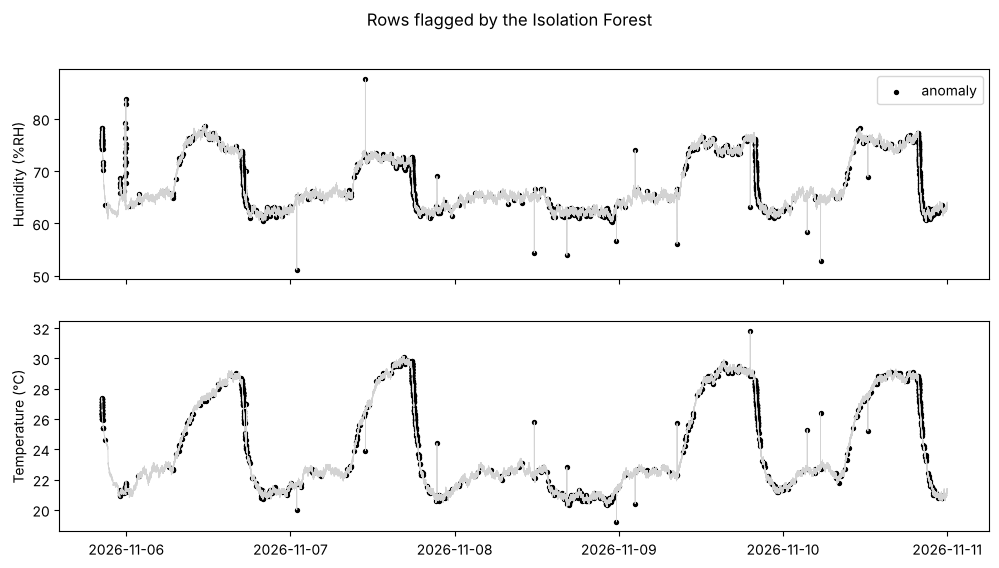

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
a = df[df['anomaly'] == 1]

ax[0].plot(df['pc_time'], df['humidity_pct'], color='lightgray', linewidth=0.6)
ax[0].scatter(a['pc_time'], a['humidity_pct'], color='black', s=8, label='anomaly')
ax[0].set_ylabel('Humidity (%RH)')
ax[0].legend()

ax[1].plot(df['pc_time'], df['temp_c'], color='lightgray', linewidth=0.6)
ax[1].scatter(a['pc_time'], a['temp_c'], color='black', s=8)
ax[1].set_ylabel('Temperature (°C)')

plt.suptitle('Rows flagged by the Isolation Forest')
plt.show()

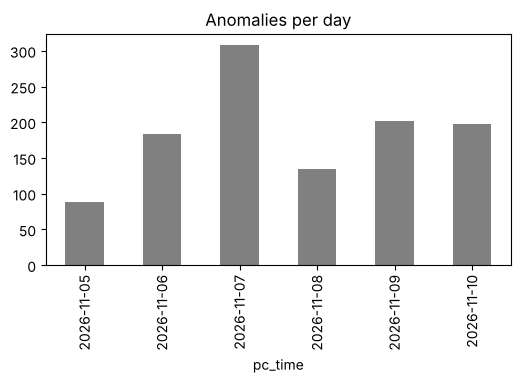

In [8]:
df.groupby(df['pc_time'].dt.date)['anomaly'].sum().plot(kind='bar', color='gray', figsize=(6, 3), title='Anomalies per day')
plt.show()

## 7. Save the model

In [9]:
joblib.dump({'model': model, 'features': FEATURES}, 'anomaly_model.pkl')
print('saved anomaly_model.pkl')

saved anomaly_model.pkl


## 8. Try it with one reading

Here humidity jumps from 64 to 82 in one step, so it should be flagged.

In [10]:
prev = {'temp_c': 25.0, 'humidity_pct': 64.0}
new = {'temp_c': 25.0, 'humidity_pct': 82.0, 'mic_peak': 40000}

row = pd.DataFrame([{
    'temp_c': new['temp_c'],
    'humidity_pct': new['humidity_pct'],
    'mic_log': np.log10(new['mic_peak']),
    'temp_jump': abs(new['temp_c'] - prev['temp_c']),
    'hum_jump': abs(new['humidity_pct'] - prev['humidity_pct']),
}])
print('Anomaly' if model.predict(row[FEATURES])[0] == -1 else 'Normal')

Anomaly


## How we're going to use this in Talos (real time)

**Purpose:** stop bad sensor readings from making bad decisions, and tell us when a sensor might be broken.

**How it runs:**
1. The same Python script that listens to `talos/readings` checks **every 2-second row** with `anomaly_model.pkl`. It only needs the current row and the previous one, so it's fast.
2. If a row is flagged:
   - it sends `anomaly = 1` to ThingsBoard, so the dashboard can show a warning and count anomalies per day
   - it tells the board to skip the AC rules for that moment, so one wrong reading can't turn the AC on or off
   - the row gets marked in the database, so we can leave it out next time we train the other models
3. If the same sensor keeps getting flagged for a few minutes, Talos can say a warning on the speaker ("check the humidity sensor").

This is why this notebook uses the **raw** `data_final.csv` and not the cleaned one: in real time the model sees the raw values, spikes included.